In [15]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt

In [16]:
# Constants
LATENT_DIM = 32        # Size of noise vector for generator input
BATCH_SIZE = 128       # Batch size for training
EPOCHS = 1000          # Number of training epochs
LEARNING_RATE = 0.0002 # Learning rate for Adam optimizers
BETAS = (0.5, 0.999)   # Betas for Adam optimizers
RANDOM_STATE = 1082    # Random seed for reproducibility
TEST_SIZE = 0.2        # Test split ratio

Conditional GAN for tabular data
- Generator: learns to generate fake tabular data conditioned on class labels.
- Discriminator: learns to distinguish real vs. fake samples, given labels.
- Training alternates between D and G updates, as in standard GANs.

In [17]:
class cGAN_Tabular:
    def __init__(self, data_dim, n_classes, latent_dim=LATENT_DIM, device=None):
        self.latent_dim = latent_dim
        self.data_dim = data_dim
        self.n_classes = n_classes
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")

        self.G = self.build_generator().to(self.device)
        self.D = self.build_discriminator().to(self.device)

        self.criterion = nn.BCELoss()
        self.optim_G = optim.Adam(self.G.parameters(), lr=LEARNING_RATE, betas=BETAS)
        self.optim_D = optim.Adam(self.D.parameters(), lr=LEARNING_RATE, betas=BETAS)

    def build_generator(self):
        return nn.Sequential(
            nn.Linear(self.latent_dim + self.n_classes, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, self.data_dim)
        )

    def build_discriminator(self):
        return nn.Sequential(
            nn.Linear(self.data_dim + self.n_classes, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.4),
            nn.Linear(256, 128),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.4),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )

    def train(self, X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, sample_interval=100, plot=True):
        # Prepare one-hot labels
        y_train = torch.tensor(y_train, dtype=torch.long)
        X_train = torch.tensor(X_train, dtype=torch.float32)
        dataset = torch.utils.data.TensorDataset(X_train, y_train)
        dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True)

        G_losses, D_losses = [], []

        for epoch in range(epochs):
            for real_data, real_labels in dataloader:
                real_data = real_data.to(self.device)
                real_labels = real_labels.to(self.device)
                batch_sz = real_data.size(0)
                real_onehot = torch.nn.functional.one_hot(real_labels, num_classes=self.n_classes).float()

                # Train Discriminator
                self.D.train()
                self.D.zero_grad()
                # Real samples
                valid = torch.ones((batch_sz, 1), device=self.device)
                fake = torch.zeros((batch_sz, 1), device=self.device)

                D_input_real = torch.cat([real_data, real_onehot], dim=1)
                D_real = self.D(D_input_real)
                d_loss_real = self.criterion(D_real, valid)

                # Fake samples
                noise = torch.randn(batch_sz, self.latent_dim, device=self.device)
                fake_labels = torch.randint(0, self.n_classes, (batch_sz,), device=self.device)
                fake_onehot = torch.nn.functional.one_hot(fake_labels, num_classes=self.n_classes).float()
                G_input = torch.cat([noise, fake_onehot], dim=1)
                fake_data = self.G(G_input)
                D_input_fake = torch.cat([fake_data.detach(), fake_onehot], dim=1)
                D_fake = self.D(D_input_fake)
                d_loss_fake = self.criterion(D_fake, fake)

                d_loss = 0.5 * (d_loss_real + d_loss_fake)
                d_loss.backward()
                self.optim_D.step()

                # Train Generator
                self.G.train()
                self.G.zero_grad()
                # Generate again for generator step
                G_input = torch.cat([noise, fake_onehot], dim=1)
                fake_data = self.G(G_input)
                D_input_fake = torch.cat([fake_data, fake_onehot], dim=1)
                D_fake = self.D(D_input_fake)
                g_loss = self.criterion(D_fake, valid)
                g_loss.backward()
                self.optim_G.step()

            G_losses.append(g_loss.item())
            D_losses.append(d_loss.item())

            if (epoch+1) % sample_interval == 0 or epoch == 0:
                print(f'[{epoch+1}/{epochs}]\tLoss_D: {d_loss.item():.4f}\tLoss_G: {g_loss.item():.4f}')

        if plot:
            plt.figure(figsize=(10, 5))
            plt.title("Generator and Discriminator Loss")
            plt.plot(G_losses, label="G")
            plt.plot(D_losses, label="D")
            plt.xlabel("Epoch")
            plt.ylabel("Loss")
            plt.legend()
            plt.show()
        return G_losses, D_losses

    def generate(self, num_samples, label_value, scaler=None):
        self.G.eval()
        z = torch.randn(num_samples, self.latent_dim, device=self.device)
        labels = torch.full((num_samples,), label_value, dtype=torch.long, device=self.device)
        labels_onehot = torch.nn.functional.one_hot(labels, num_classes=self.n_classes).float()
        G_input = torch.cat([z, labels_onehot], dim=1)
        with torch.no_grad():
            synth = self.G(G_input).cpu().numpy()
        if scaler is not None:
            synth = scaler.inverse_transform(synth)
        return synth

In [18]:
# Load Data
df = pd.read_csv("../../../Datasets/csv/spoofing-merged-gps-only.csv")
df.columns = df.columns.str.replace('[\\[\\]<>]', '_', regex=True)
drop_cols = ['timestamp', 'label']
X = df.drop(columns=drop_cols).values
labels = df['label']

In [19]:
# Preview raw data
print("Raw data preview:")
print(df.head())
print("\nShape:", df.shape)
print("Label distribution:\n", df['label'].value_counts())

Raw data preview:
   timestamp      q_0_      q_1_      q_2_      q_3_  delta_q_reset_0_  \
0  258725029 -0.325207  0.010554 -0.006518  0.945561          0.999995   
1  258842609 -0.325207  0.010554 -0.006518  0.945561          0.999995   
2  258847608 -0.325207  0.010554 -0.006518  0.945561          0.999995   
3  258852607 -0.325204  0.010556 -0.006517  0.945562          0.999995   
4  258902598 -0.325214  0.010552 -0.006501  0.945559          0.999995   

   delta_q_reset_1_  delta_q_reset_2_  delta_q_reset_3_  quat_reset_counter  \
0     -4.610000e-10      1.580000e-09          0.003237                   3   
1     -4.610000e-10      1.580000e-09          0.003237                   3   
2     -4.610000e-10      1.580000e-09          0.003237                   3   
3     -4.610000e-10      1.580000e-09          0.003237                   3   
4     -4.610000e-10      1.580000e-09          0.003237                   3   

   ...  v_z_valid  xy_reset_counter  z_reset_counter  vxy_rese

In [20]:
# Preprocess Data
# Label encoding
if labels.dtype == object or labels.dtype.name == 'category':
    le = LabelEncoder()
    y = le.fit_transform(labels)
else:
    y = labels.values

n_classes = len(np.unique(y))
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

[1/1000]	Loss_D: 0.6787	Loss_G: 0.6582
[100/1000]	Loss_D: 0.6041	Loss_G: 1.2618
[200/1000]	Loss_D: 0.4675	Loss_G: 1.6228
[300/1000]	Loss_D: 0.4364	Loss_G: 1.7776
[400/1000]	Loss_D: 0.3513	Loss_G: 2.0710
[500/1000]	Loss_D: 0.3647	Loss_G: 2.2835
[600/1000]	Loss_D: 0.4036	Loss_G: 2.5129
[700/1000]	Loss_D: 0.3807	Loss_G: 1.9347
[800/1000]	Loss_D: 0.2578	Loss_G: 2.4399
[900/1000]	Loss_D: 0.3547	Loss_G: 2.1756
[1000/1000]	Loss_D: 0.4037	Loss_G: 2.7000


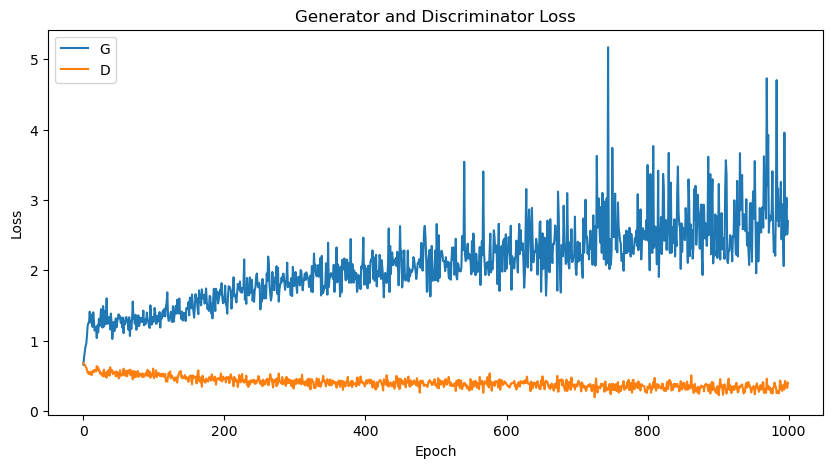

In [21]:
# Train cGAN
cgan = cGAN_Tabular(
    data_dim=X_train.shape[1],
    n_classes=n_classes,
    latent_dim=LATENT_DIM
)
G_losses, D_losses = cgan.train(X_train, y_train, epochs=EPOCHS, batch_size=BATCH_SIZE, sample_interval=100, plot=True)

In [22]:
# Generate synthetic data
n_class0 = np.sum(y_train == 0)
n_class1 = np.sum(y_train == 1)

gen_samples_0 = cgan.generate(n_class0, label_value=0, scaler=scaler)
gen_samples_1 = cgan.generate(n_class1, label_value=1, scaler=scaler)

gen_df_0 = pd.DataFrame(gen_samples_0, columns=df.drop(columns=drop_cols).columns)
gen_df_1 = pd.DataFrame(gen_samples_1, columns=df.drop(columns=drop_cols).columns)
gen_df_0['label'] = "benign"
gen_df_1['label'] = "malicious"

df_gan = pd.concat([gen_df_0, gen_df_1], ignore_index=True, sort=False)
df_gan = df_gan.sample(frac=1).reset_index(drop=True)

In [23]:
# Preview the synthetic data
print("\nSynthetic Data Preview: ")
print(df_gan.head())
print("\nSynthetic data shape:", df_gan.shape)
print("\nSynthetic label distribution:")
print(df_gan['label'].value_counts())


Synthetic Data Preview: 
       q_0_      q_1_      q_2_      q_3_  delta_q_reset_0_  delta_q_reset_1_  \
0 -0.375873  0.001969  0.002548  0.925084          1.000022          0.000599   
1 -0.365269 -0.014397  0.033519  0.923847          1.004067          0.002174   
2 -0.374351 -0.002846 -0.008905  0.926949          0.997348          0.002479   
3 -0.365603 -0.007269  0.035027  0.924870          0.998134          0.002546   
4 -0.377599  0.006626 -0.006627  0.924142          1.001860         -0.001094   

   delta_q_reset_2_  delta_q_reset_3_  quat_reset_counter      lat_x  ...  \
0          0.000432          0.002063            2.999022  36.204823  ...   
1         -0.004773          0.000563            3.003201  36.204826  ...   
2          0.000649          0.005015            3.000262  36.204819  ...   
3          0.001451          0.004114            2.996911  36.204819  ...   
4          0.000485          0.003445            2.999113  36.204819  ...   

   v_z_valid  xy_reset_c

In [27]:
# Save synthetic data to CSV
df_gan.to_csv("../../../datasets/csv/syntheticSpoofing_cgan_data.csv", index=False)
print("Synthetic data saved to ../../../syntheticSpoofing_gan_data.csv")

Synthetic data saved to ../../../syntheticSpoofing_gan_data.csv
